# Rate of Change

**Question:** Did some patients develop a stronger tendency towards diabetes between the two measurement dates?

The blood values (glucose, blood pressure, insulin) were measured twice: on **2022-12-01** and **2022-12-13**.
The diagnosis (`outcome`) exists only **once** per patient, so we can't see whether the diagnosis changed.
What we *can* check: **did the blood values get worse?**

For glucose (2-hour oral glucose tolerance test) there are medical reference ranges:

| Glucose (mg/dl) | Meaning |
|:--|:--|
| below 140 | normal |
| 140 - 199 | prediabetes (impaired glucose tolerance) |
| 200 and above | diabetes |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data/blood_data.csv")

# Keep only patients with a diagnosis (they were measured on both dates)
df = df.dropna(subset=["outcome"])
print(df["measurement_date"].value_counts())

measurement_date
2022-12-01    768
2022-12-13    768
Name: count, dtype: int64


# 1. One row per patient

Right now every patient has two rows (one per date). We turn this into **one row per patient**
with one column per value and date, e.g. `glucose_2022-12-01` and `glucose_2022-12-13`.

In [3]:
values = ["glucose", "bloodpressure", "insulin"]

wide = df.pivot(index="patientid", columns="measurement_date", values=values)
wide.columns = [f"{value}_{date}" for value, date in wide.columns]  # flatten the column names
wide["outcome"] = df.groupby("patientid")["outcome"].first().astype(int)

wide.head()

,glucose_2022-12-01,glucose_2022-12-13,bloodpressure_2022-12-01,bloodpressure_2022-12-13,insulin_2022-12-01,insulin_2022-12-13,outcome
patientid,,,,,,,
1,172,148,117,72,80,0,1
2,54,85,93,66,80,0,0
3,168,183,100,64,1,0,1
4,53,89,39,66,26,94,0
5,184,137,116,40,54,168,1


# 2. Can we trust the data?

Before measuring change, we check if the two measurements make sense together.
The same person, measured 12 days apart, should have **similar** values:
someone with high glucose on day 1 should still have rather high glucose on day 13.
So the values of both dates should be **strongly correlated**.

In [4]:
for value in values:
    first, second = wide[f"{value}_2022-12-01"], wide[f"{value}_2022-12-13"]
    print(f"{value:14s} correlation between the two dates: {first.corr(second):.3f}")

glucose        correlation between the two dates: 0.002
bloodpressure  correlation between the two dates: -0.034
insulin        correlation between the two dates: -0.045


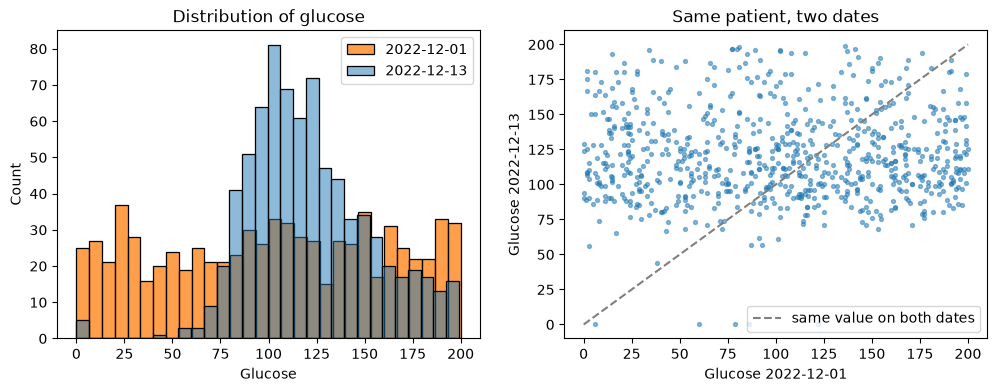

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Left: distribution of glucose on both dates
sns.histplot(wide["glucose_2022-12-01"], bins=30, color="tab:orange", label="2022-12-01", ax=axes[0])
sns.histplot(wide["glucose_2022-12-13"], bins=30, color="tab:blue", alpha=0.5, label="2022-12-13", ax=axes[0])
axes[0].set_xlabel("Glucose")
axes[0].set_title("Distribution of glucose")
axes[0].legend()

# Right: every dot is one patient. Similar values on both dates -> dots along the diagonal
axes[1].scatter(wide["glucose_2022-12-01"], wide["glucose_2022-12-13"], s=8, alpha=0.5)
axes[1].plot([0, 200], [0, 200], color="grey", linestyle="--", label="same value on both dates")
axes[1].set_xlabel("Glucose 2022-12-01")
axes[1].set_ylabel("Glucose 2022-12-13")
axes[1].set_title("Same patient, two dates")
axes[1].legend()
plt.show()

**What we see:**
- The correlation between the two dates is **≈ 0** for all values. Someone's glucose on 12-01 tells us nothing about their glucose on 12-13.
- On 2022-12-13 glucose has the typical bell shape around 120. On 2022-12-01 it is **flat between 0 and 200** -
  every value is about equally common, including values like 20 that are impossible for a living person.
- The scatter plot is a **random cloud**, not a line along the diagonal.

→ The values from 2022-12-01 look like **random numbers**, not real measurements.

# 3. Change per patient

Even so, let's calculate the change - to see what we *would* conclude without the check above.

In [6]:
for value in values:
    wide[f"{value}_change"] = wide[f"{value}_2022-12-13"] - wide[f"{value}_2022-12-01"]

wide[[f"{value}_change" for value in values]].describe().round(1)

,glucose_change,bloodpressure_change,insulin_change
count,768.0,768.0,768.0
mean,18.9,6.1,31.4
std,66.5,40.9,120.2
min,-122.0,-120.0,-100.0
25%,-34.2,-26.0,-49.0
50%,15.5,7.0,-7.0
75%,70.2,39.0,79.2
max,179.0,102.0,824.0


In [7]:
# Glucose category on each date (medical reference ranges, see top)
bins, labels = [-1, 139, 199, 1000], ["normal", "prediabetes", "diabetes"]
wide["category_2022-12-01"] = pd.cut(wide["glucose_2022-12-01"], bins=bins, labels=labels)
wide["category_2022-12-13"] = pd.cut(wide["glucose_2022-12-13"], bins=bins, labels=labels)

# Rows: category on the first date, columns: category on the second date
pd.crosstab(wide["category_2022-12-01"], wide["category_2022-12-13"])

category_2022-12-13,normal,prediabetes
category_2022-12-01,,
normal,390,135
prediabetes,179,62
diabetes,2,0


In [8]:
# Patients who moved from "normal" to "prediabetes" - the ones with a "tendency towards diabetes"
worse = wide[(wide["category_2022-12-01"] == "normal") & (wide["category_2022-12-13"] == "prediabetes")]
print(len(worse), "of", len(wide), "patients moved from normal to prediabetes")

worse.sort_values("glucose_change", ascending=False)[["glucose_2022-12-01", "glucose_2022-12-13", "glucose_change", "outcome"]].head(10)

135 of 768 patients moved from normal to prediabetes


,glucose_2022-12-01,glucose_2022-12-13,glucose_change,outcome
patientid,,,,
607,2,181,179,1
400,15,193,178,1
46,6,180,174,1
456,2,175,173,1
57,21,187,166,1
647,2,167,165,1
371,9,173,164,1
41,17,180,163,0
207,34,196,162,1


At first sight this looks like a finding: 135 patients got worse. But look closer:
- The biggest "increases" start from glucose values like **2 or 6** on 12-01 - impossible for a living person.
- In the table above, **179 patients got better** (prediabetes → normal) at the same time. Random values move in both directions.

# 4. Is the change related to the diagnosis?

In [9]:
# Correlation with the outcome: first date, second date and change
pd.DataFrame({
    value: {
        "2022-12-01": wide[f"{value}_2022-12-01"].corr(wide["outcome"]),
        "2022-12-13": wide[f"{value}_2022-12-13"].corr(wide["outcome"]),
        "change":     wide[f"{value}_change"].corr(wide["outcome"]),
    }
    for value in values
}).round(3)

,glucose,bloodpressure,insulin
2022-12-01,-0.057,-0.044,0.040
2022-12-13,0.467,0.065,0.131
change,0.275,0.069,0.115


The glucose **change** seems to be related to the diagnosis (≈ 0.28). But that is misleading:
change = value on 12-13 **minus** value on 12-01. The 12-01 part is random, so the change only
"inherits" the relationship of the 12-13 value (≈ 0.47) - weakened by the random noise.
The change itself carries **no extra information**.

# 5. Conclusion

- **We can't answer the question with this data.** The values from 2022-12-01 behave like random numbers
  (flat distribution, impossible values, no correlation with the same patient 12 days later, no relationship to the diagnosis).
- Every "change" we calculate is therefore mostly **noise**. The list of patients who "got worse" (section 3)
  is a list of random fluctuations, not real patients at risk.
- Even with real data, **12 days** is a very short time - diabetes develops over months or years.
- To really answer the question we would need: reliable measurements, more dates over a longer period,
  and ideally a diagnosis per date. → Ask the data owner what the 2022-12-01 data actually is.